# Alzheimer's MRI Classification with Grad-CAM

This notebook trains a CNN to classify OASIS MRI slices into four classes:

- Mild Dementia
- Moderate Dementia
- Non Demented
- Very mild Dementia

It also calculates evaluation metrics and generates Grad-CAM heatmaps to show which MRI regions influenced the model's predictions.



## 1. Imports

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

print("TensorFlow version:", tf.__version__)

/opt/anaconda3/envs/oasis_mri/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow version: 2.16.2


## 2. Download and locate dataset

The KaggleHub download places the class folders inside a `Data` folder.

In [2]:
path = kagglehub.dataset_download("ninadaithal/imagesoasis")
print("Dataset path:", path)

data_dir = os.path.join(path, "Data")

print("Using data directory:", data_dir)
print("Folders found:", os.listdir(data_dir))

Dataset path: /Users/tylercrosbie/.cache/kagglehub/datasets/ninadaithal/imagesoasis/versions/1
Using data directory: /Users/tylercrosbie/.cache/kagglehub/datasets/ninadaithal/imagesoasis/versions/1/Data
Folders found: ['Mild Dementia', 'Very mild Dementia', 'Moderate Dementia', 'Non Demented']


## 3. Settings

The class order is explicitly defined so the label mapping stays consistent.

In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
NUM_CLASSES = 4

class_names = [
    "Mild Dementia",
    "Moderate Dementia",
    "Non Demented",
    "Very mild Dementia"
]

print("Class order:")
for i, name in enumerate(class_names):
    print(i, name)

Class order:
0 Mild Dementia
1 Moderate Dementia
2 Non Demented
3 Very mild Dementia


## 4. Load training and validation datasets

In [4]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    class_names=class_names
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    class_names=class_names
)

print("Classes:", train_ds_raw.class_names)

Found 86437 files belonging to 4 classes.
Using 69150 files for training.
Found 86437 files belonging to 4 classes.
Using 17287 files for validation.
Classes: ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']


## 5. Improve dataset performance

Caching may use a lot of RAM for this dataset. If your computer runs out of memory, remove `.cache()` from the training and validation pipelines.

In [5]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds_raw.shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds_raw.prefetch(AUTOTUNE)

## 6. Compute class weights

This handles the imbalanced dataset. Smaller classes receive larger weights, so the model is penalized more for misclassifying underrepresented classes.

In [6]:
y_train_indices = []

for _, y_batch in train_ds_raw.unbatch():
    y_train_indices.append(np.argmax(y_batch.numpy()))

y_train_indices = np.array(y_train_indices)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_indices),
    y=y_train_indices
)

class_weights = {
    i: float(weight) for i, weight in enumerate(class_weights_array)
}

print("Class weights:")
for i, weight in class_weights.items():
    print(f"{class_names[i]}: {weight:.4f}")

Class weights:
Mild Dementia: 4.3611
Moderate Dementia: 45.2552
Non Demented: 0.3210
Very mild Dementia: 1.5799


2026-06-07 11:41:52.332737: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## 7. Build the model

This model uses EfficientNetB0 as the transfer-learning backbone. A custom convolutional layer named `gradcam_conv` is added so Grad-CAM can generate heatmaps from the final spatial feature maps.

Horizontal flipping is intentionally not used because left/right flips can be anatomically misleading for brain MRI scans.

In [7]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.10)
], name="data_augmentation")

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3), name="input_image")
x = data_augmentation(inputs)
x = preprocess_input(x)

x = base_model(x, training=False)

# Smaller than 128 filters to reduce overfitting and training time.
x = layers.Conv2D(
    64,
    kernel_size=3,
    padding="same",
    activation="relu",
    name="gradcam_conv"
)(x)

x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.35, name="dropout")(x)

outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_output")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gradcam_conv (Conv2D)           │ (None, 7, 7, 64)       │       737,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_output (Dense)            │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,787,175 (18.26 MB)

 Trainable params: 737,604 (2.81 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 8. Train feature-extraction model

This is the safest training phase. EfficientNet is frozen, and only the custom classification head is trained.

Based on your previous output, this phase performed much better than fine-tuning.

In [8]:
feature_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_feature_extraction_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=feature_callbacks
)

# Save final restored best model from this phase.
model.save("best_oasis_model.keras")

Epoch 1/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 787s 361ms/step - accuracy: 0.5457 - loss: 1.0408 - val_accuracy: 0.7290 - val_loss: 0.6811 - learning_rate: 0.0010
Epoch 2/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 1481s 683ms/step - accuracy: 0.6787 - loss: 0.6794 - val_accuracy: 0.7883 - val_loss: 0.4972 - learning_rate: 0.0010
Epoch 3/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 2616s 1s/step - accuracy: 0.7084 - loss: 0.5726 - val_accuracy: 0.8488 - val_loss: 0.3750 - learning_rate: 0.0010
Epoch 4/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 918s 422ms/step - accuracy: 0.7371 - loss: 0.4931 - val_accuracy: 0.8255 - val_loss: 0.3973 - learning_rate: 0.0010
Epoch 5/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 998s 459ms/step - accuracy: 0.7636 - loss: 0.4125 - val_accuracy: 0.8499 - val_loss: 0.3471 - learning_rate: 0.0010
Epoch 6/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 971s 446ms/step - accuracy: 0.7792 - loss: 0.4005 - val_accuracy: 0.8620 - val_loss: 0.3134 - learning_rate: 0.0010
Epoch 7/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 2024s 934ms

2026-06-07 14:25:17.828338: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:16: Filling up shuffle buffer (this may take a while): 332 of 1000
2026-06-07 14:25:37.765334: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:16: Filling up shuffle buffer (this may take a while): 938 of 1000
2026-06-07 14:25:39.064421: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


2161/2161 ━━━━━━━━━━━━━━━━━━━━ 4072s 2s/step - accuracy: 0.7983 - loss: 0.3319 - val_accuracy: 0.8768 - val_loss: 0.2782 - learning_rate: 0.0010
Epoch 9/15


2026-06-07 15:33:10.000738: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:16: Filling up shuffle buffer (this may take a while): 352 of 1000
2026-06-07 15:33:27.035507: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


2161/2161 ━━━━━━━━━━━━━━━━━━━━ 1398s 634ms/step - accuracy: 0.8073 - loss: 0.3242 - val_accuracy: 0.8326 - val_loss: 0.4347 - learning_rate: 0.0010
Epoch 10/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 4169s 2s/step - accuracy: 0.8138 - loss: 0.3302 - val_accuracy: 0.9104 - val_loss: 0.2180 - learning_rate: 0.0010
Epoch 11/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 7415s 3s/step - accuracy: 0.8321 - loss: 0.2728 - val_accuracy: 0.9011 - val_loss: 0.2224 - learning_rate: 0.0010
Epoch 12/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 974s 448ms/step - accuracy: 0.8357 - loss: 0.2692 - val_accuracy: 0.8979 - val_loss: 0.2344 - learning_rate: 0.0010
Epoch 13/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 1058s 486ms/step - accuracy: 0.8574 - loss: 0.2179 - val_accuracy: 0.9187 - val_loss: 0.1946 - learning_rate: 3.0000e-04
Epoch 14/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 1609s 741ms/step - accuracy: 0.8647 - loss: 0.2106 - val_accuracy: 0.9184 - val_loss: 0.1888 - learning_rate: 3.0000e-04
Epoch 15/15
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 1044s 48

## 9. Plot training curves

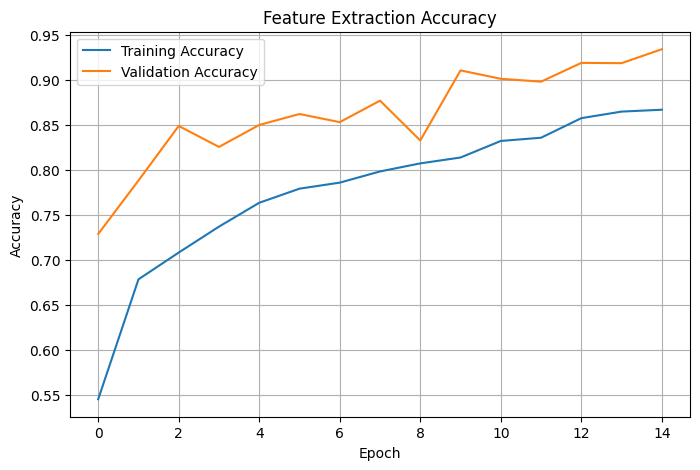

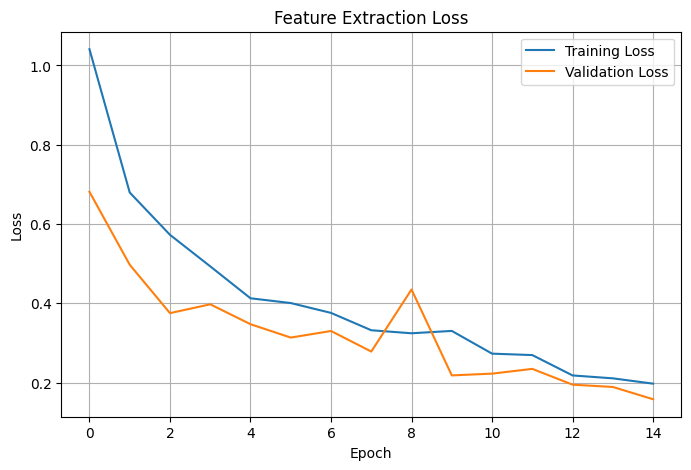

In [9]:
def plot_training_curves(history, title_prefix="Feature Extraction"):
    hist = history.history

    plt.figure(figsize=(8, 5))
    plt.plot(hist["accuracy"], label="Training Accuracy")
    plt.plot(hist["val_accuracy"], label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title_prefix} Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(hist["loss"], label="Training Loss")
    plt.plot(hist["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title_prefix} Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_training_curves(history)

## 10. Optional fine-tuning

Your earlier fine-tuning output showed that fine-tuning **reduced** validation accuracy from about 93.9% to about 78%. Because of that, this section is optional and disabled by default.

If you enable it, the learning rate is very small and the notebook compares the fine-tuned model against the feature-extraction model.

In [10]:
RUN_FINE_TUNING = False

if RUN_FINE_TUNING:
    # Load the best feature-extraction model before fine-tuning.
    model = tf.keras.models.load_model("best_feature_extraction_model.keras")

    # Find EfficientNet inside the model.
    base_model = model.get_layer("efficientnetb0")
    base_model.trainable = True

    # Freeze most layers and only fine-tune the final part.
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-6),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    fine_tune_callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            "best_fine_tuned_model.keras",
            monitor="val_loss",
            save_best_only=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=1,
            min_lr=1e-7
        )
    ]

    fine_tune_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=5,
        class_weight=class_weights,
        callbacks=fine_tune_callbacks
    )

    model.save("best_oasis_model.keras")
    plot_training_curves(fine_tune_history, title_prefix="Fine-Tuning")

else:
    print("Fine-tuning skipped. Using best feature-extraction model.")
    model = tf.keras.models.load_model("best_feature_extraction_model.keras")

Fine-tuning skipped. Using best feature-extraction model.


## 11. Evaluate model

This section calculates:

- Accuracy
- Macro F1
- Mild Dementia F1
- Moderate Dementia F1
- Non Demented F1
- Very mild Dementia F1
- Classification report
- Confusion matrix

In [11]:
y_true = []
y_pred = []

for images, labels_batch in val_ds:
    preds = model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels_batch.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
f1_per_class = f1_score(y_true, y_pred, average=None)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}")
print()

for class_name, f1 in zip(class_names, f1_per_class):
    print(f"{class_name} F1 Score: {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

Accuracy: 0.9339
Macro F1 Score: 0.9149

Mild Dementia F1 Score: 0.9367
Moderate Dementia F1 Score: 0.9298
Non Demented F1 Score: 0.9566
Very mild Dementia F1 Score: 0.8367

Classification Report:
                    precision    recall  f1-score   support

     Mild Dementia       0.88      1.00      0.94      1038
 Moderate Dementia       0.87      1.00      0.93       106
      Non Demented       0.98      0.93      0.96     13360
Very mild Dementia       0.77      0.92      0.84      2783

          accuracy                           0.93     17287
         macro avg       0.88      0.96      0.91     17287
      weighted avg       0.94      0.93      0.94     17287



2026-06-07 20:30:49.357459: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## 12. Confusion matrix

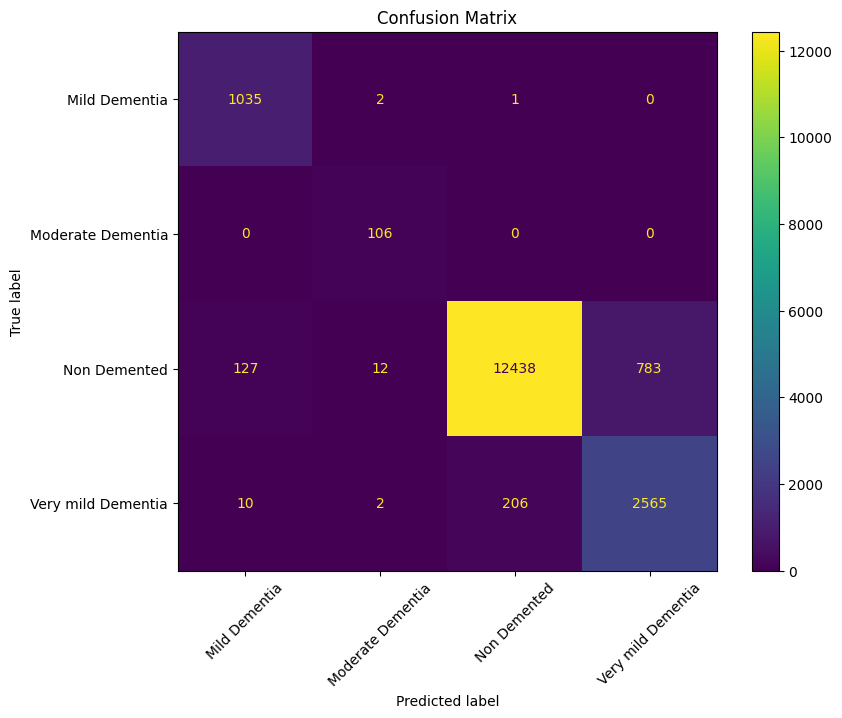

In [12]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("Confusion Matrix")
plt.show()

## 13. Grad-CAM functions

In [13]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name="gradcam_conv", pred_index=None):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    max_val = tf.reduce_max(heatmap)

    if max_val == 0:
        return np.zeros_like(heatmap.numpy()), predictions.numpy()

    heatmap = tf.maximum(heatmap, 0) / max_val

    return heatmap.numpy(), predictions.numpy()


def show_gradcam(image, true_label=None, model=model, class_names=class_names, alpha=0.4):
    img_array = tf.expand_dims(image, axis=0)

    heatmap, predictions = make_gradcam_heatmap(
        img_array,
        model,
        last_conv_layer_name="gradcam_conv"
    )

    pred_class_index = np.argmax(predictions[0])
    pred_class_name = class_names[pred_class_index]
    confidence = predictions[0][pred_class_index]

    image_np = image.numpy().astype("uint8")

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (image_np.shape[0], image_np.shape[1])
    ).numpy().squeeze()

    true_label_text = ""
    if true_label is not None:
        true_label_text = f"True: {class_names[int(true_label)]}\n"

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(image_np)
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(image_np)
    plt.imshow(heatmap_resized, cmap="jet", alpha=alpha)
    plt.title(f"{true_label_text}Pred: {pred_class_name}\nConfidence: {confidence:.2f}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

## 14. Display Grad-CAM examples

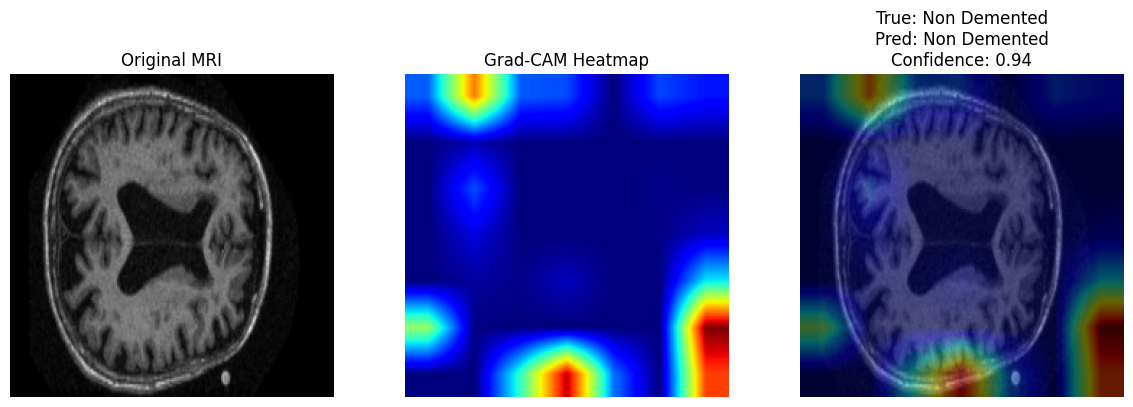

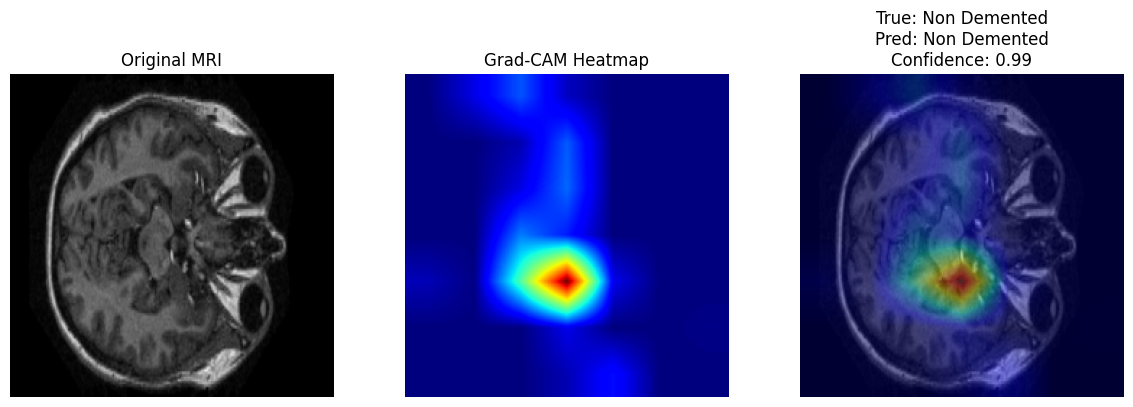

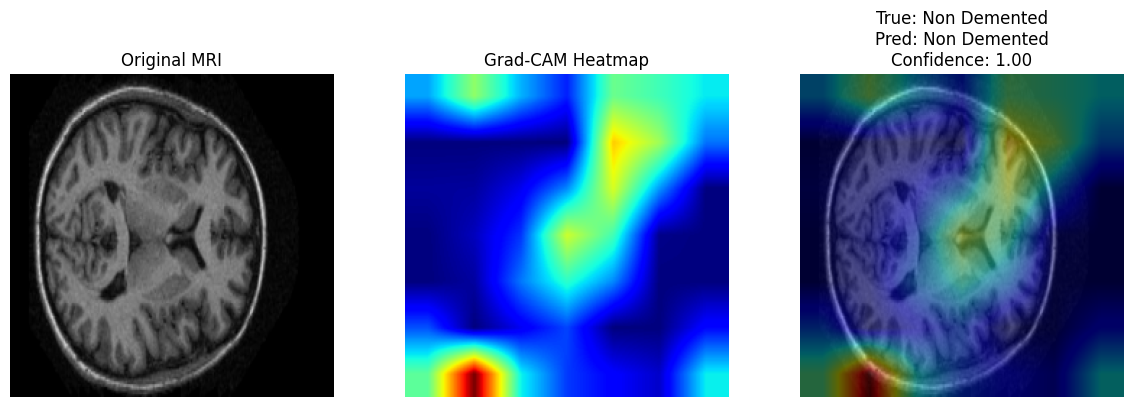

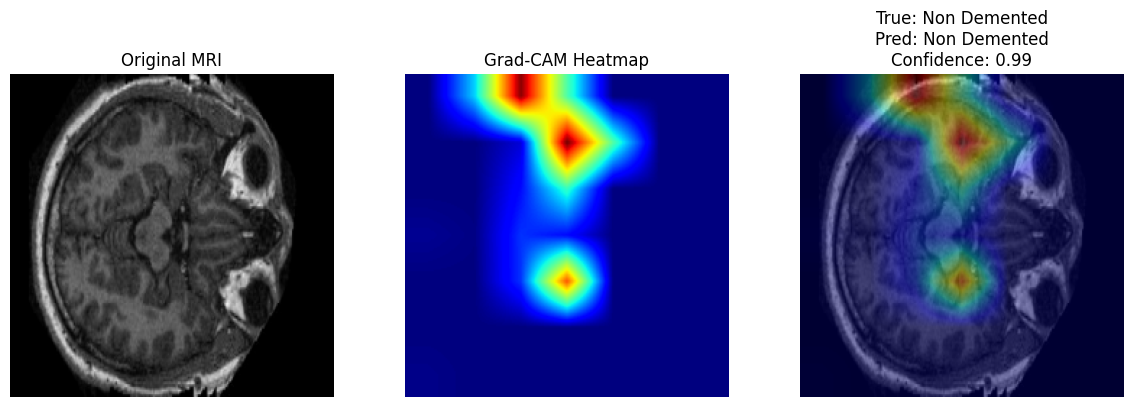

2026-06-07 20:30:50.839053: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [14]:
for images, labels_batch in val_ds.take(1):
    label_indices = np.argmax(labels_batch.numpy(), axis=1)

    for i in range(min(4, len(images))):
        show_gradcam(images[i], true_label=label_indices[i])

## 15. Notes for report

Based on the training output, the feature-extraction stage performed well, reaching strong validation accuracy. However, fine-tuning originally reduced validation performance, likely because the learning rate/class weighting made the pretrained layers update too aggressively. Therefore, this notebook keeps fine-tuning optional and defaults to the best feature-extraction model.

The model accounts for class imbalance by using class weights during training. The Moderate Dementia class receives the largest weight because it has the fewest examples, so mistakes on that class are penalized more heavily.